# mRFP-DsRed 

Notebook implementing reconstruction of raw measuremenets of mRFP-DsRed sample, acquired using Hadamard motifs. 

The raw data and motif measurements must first be preprocessed by running *main_preprocess_mRFP-DsRed.py*

Two reconstruction methods are implemented:
- Direct Reconstruction, using the pseudo inverse: $\bm F_\lambda = \bm H^\dagger \bm M_\lambda$
- Direct Reconstruction + Unet: $\bm F_\lambda = \mathcal G_\theta (\bm H^\dagger \bm M_\lambda)$
- Tikhonov Regularisation  + Unet: $\bm F_\lambda = \mathcal G_\theta ( \bm \Sigma \bm H^\top ( \bm {H\Sigma H^\top} + \bm \Gamma)^{-1}\bm M_\lambda )$

Where $\mathcal G_\theta$ is a pre-trained neural network with parameters $\theta$ acting in the spatial domain. 


## Load Hadamard matrices

Load prepped hadamard motifs and compare to target patterns

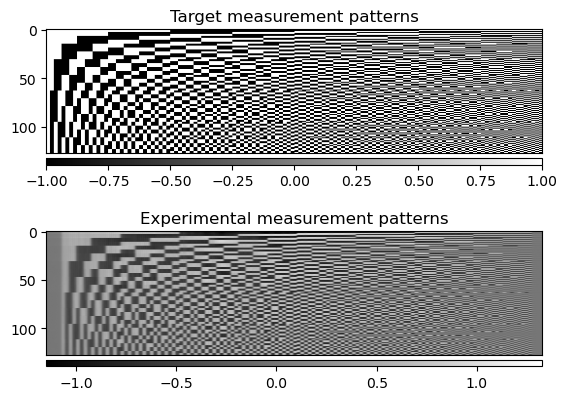

In [1]:
import collections
collections.Callable = collections.abc.Callable

fig_folder = './figure/'

#%% Load experimental measurement matrix (after split compensation)
from pathlib import Path
from spyrit.misc.disp import imagesc, add_colorbar, noaxis
import matplotlib.pyplot as plt
from spyrit.misc.walsh_hadamard import walsh_matrix
import numpy as np
import torch
   
#%% Init physics operators for experimental patterns
from spyrit.core.meas import LinearSplit
from spyrit.core.noise import Poisson
#from spyrit_dev import SplitPoisson1d
from spyrit.core.prep import UnsplitRescale, Rerange, UnsplitRescaleEstim
from spyrit.core.recon import TikhoNet, PinvNet
from spyrit.core.nnet import Unet, Identity
from spyrit.core.train import load_net
import torch.nn as nn
from typing import OrderedDict

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
save_rec = True
save_fig = True

M = 128
N = 512


alpha = 50
div = 1.5 

data_folder = './data/2023_02_28_mRFP_DsRed_3D/'
mat_folder = '/Reconstruction/Mat_rc/'
prep_folder = '/Preprocess/' 
save_folder = '/Reconstruction/hypercube/' + f'tikhonet{alpha}_div{div}'

nbin = 20*4
mudark = 106.0
sigdark = 5.0
gain = 2.65

# load
H_exp = np.load(Path(data_folder + mat_folder) / f'measurement_matrix_{M}_{N}.npy')
H_exp /= H_exp[0,16:500].mean()


H_tar = walsh_matrix(N)
H_tar = H_tar[:M]

# plot
f, axs = plt.subplots(2, 1)
axs[0].set_title('Target measurement patterns')
im = axs[0].imshow(H_tar, cmap='gray') 
add_colorbar(im, 'bottom')
axs[0].get_xaxis().set_visible(False)

axs[1].set_title('Experimental measurement patterns')
im = axs[1].imshow(H_exp, cmap='gray') 
add_colorbar(im, 'bottom')
axs[1].get_xaxis().set_visible(False)


H = torch.from_numpy(H_exp)


## Reconstruction

### Set up

In [2]:

channel = 10, 55, 100  # to be plotted
Nl, Nh, Nc = 512, 128, 128 # shape of preprocessed data
T_list = [*range(4, 8), *range(9, 25)] # slice indices, Run0008 corrupted

# covariance prior in the image domain
stat_folder = './stat/'
cov_file   = f'Cov_1_{N}x{N}.npy'
sigma = np.load(Path(stat_folder) / cov_file)

# Load net
alpha = 50
net_prefix = f'tikho-net_unet_imagenet_ph_{alpha}'
net_suffix = 'N_512_M_128_epo_20_lr_0.001_sss_10_sdr_0.5_bs_20_reg_1e-07.pth'

even_index = range(0, 2 *M, 2)
odd_index = range(1, 2 *M, 2)


### TIKHONET

Reconstruction using Tikhonov Regularisation and Unet Denoiser

The covariance matrix can be downloaded [here] (https://pilot-warehouse.creatis.insa-lyon.fr/#collection/63caa9497bef31845d991351/folder/6464d58285f48d3da0718935)

The model can be downloaded [here](https://pilot-warehouse.creatis.insa-lyon.fr/#collection/63caa9497bef31845d991351/folder/6464d5f585f48d3da071893c)

Model Loaded: ./model/tikho-net_unet_imagenet_ph_50_exp_N_512_M_128_epo_20_lr_0.001_sss_10_sdr_0.5_bs_20_reg_1e-07.pth
Loaded: RUN0004_Had_512_128_128
Pos data: range=30929.0 counts; mean=9391.822192072868 counts
reconstructing batch 0--16
reconstructing batch 16--32
reconstructing batch 32--48
reconstructing batch 48--64
reconstructing batch 64--80
reconstructing batch 80--96
reconstructing batch 96--112
reconstructing batch 112--128
Loaded: RUN0005_Had_512_128_128
Pos data: range=9803.0 counts; mean=9372.537360072136 counts
reconstructing batch 0--16
reconstructing batch 16--32
reconstructing batch 32--48
reconstructing batch 48--64
reconstructing batch 64--80
reconstructing batch 80--96
reconstructing batch 96--112
reconstructing batch 112--128
Loaded: RUN0006_Had_512_128_128
Pos data: range=7724.0 counts; mean=9408.137484073639 counts
reconstructing batch 0--16
reconstructing batch 16--32
reconstructing batch 32--48
reconstructing batch 48--64
reconstructing batch 64--80
reconstruc

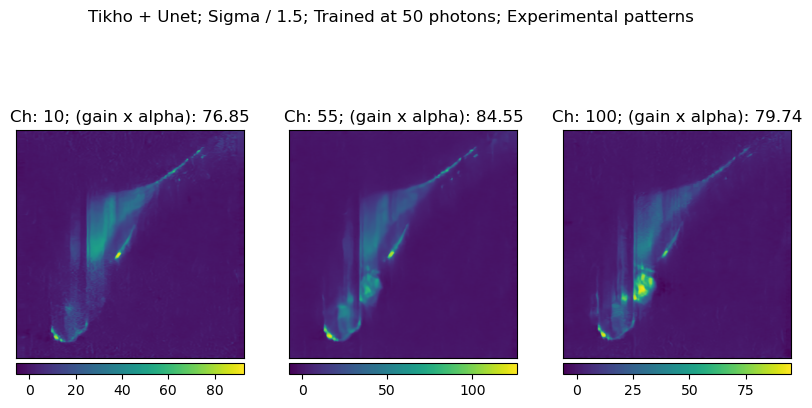

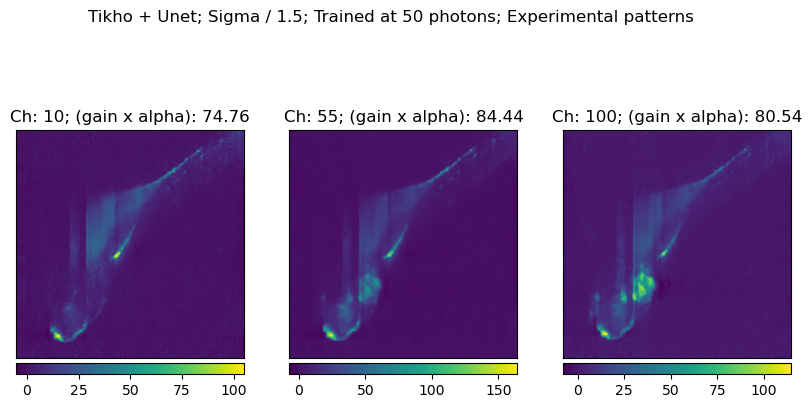

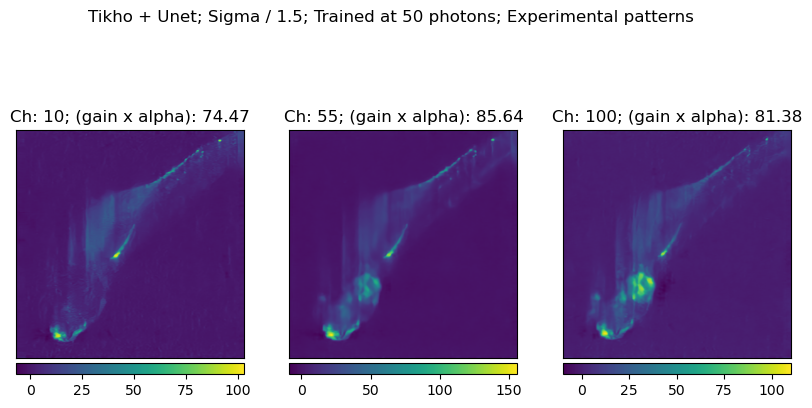

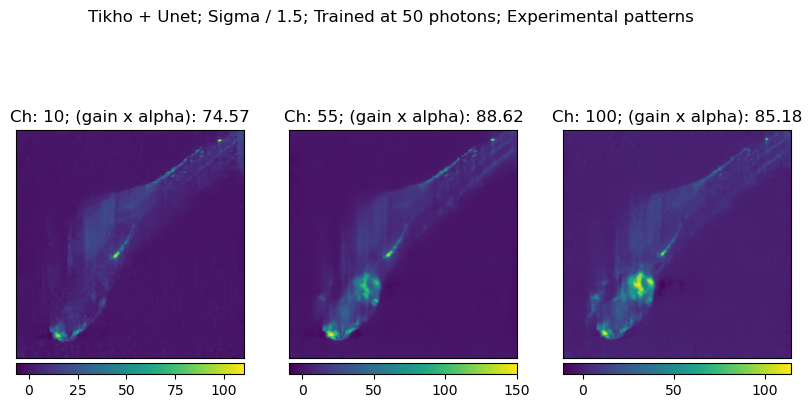

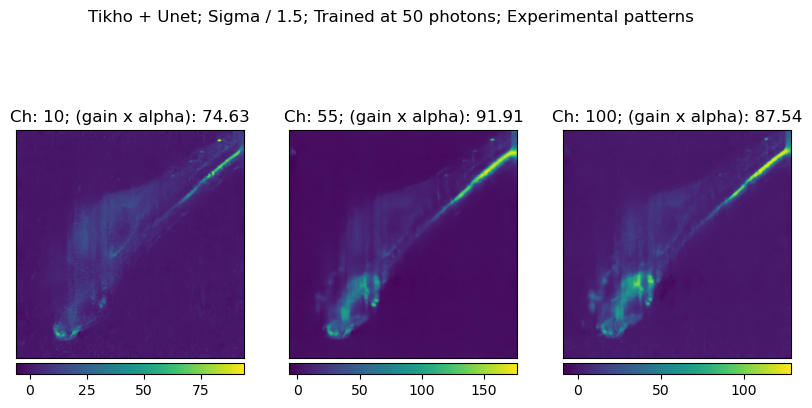

...

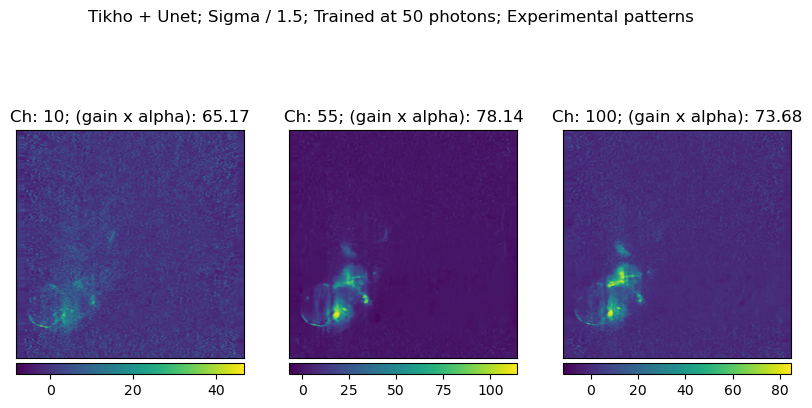

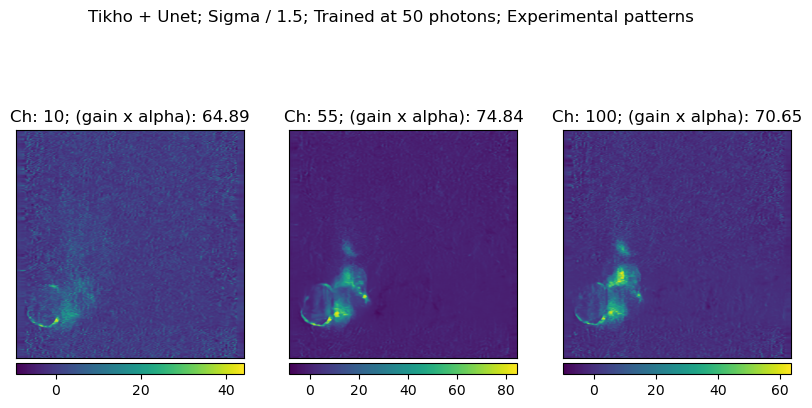

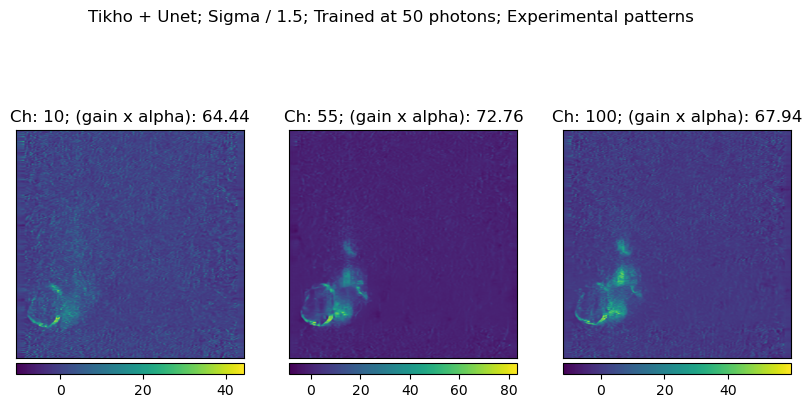

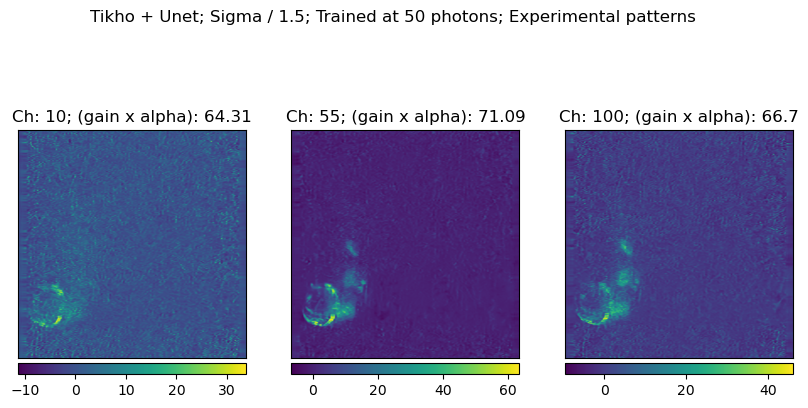

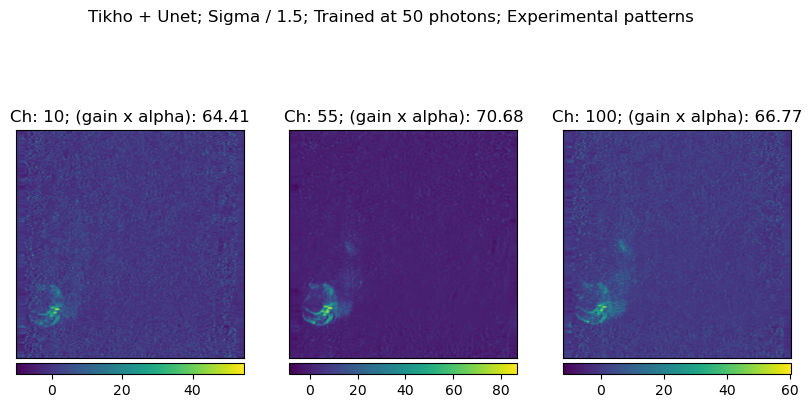

In [3]:
# define measurement operators
noise = Poisson(alpha)
linop = LinearSplit(torch.from_numpy(H_exp), noise_model=noise, device=device)
rerange = Rerange((0, 1), (-1, 1))


denoiser = OrderedDict({"rerange": rerange, "denoi": Unet(), "rerange_inv": rerange.inverse()})
denoiser = nn.Sequential(denoiser)

title = './model/' + net_prefix + '_exp_' + net_suffix
load_net(title, denoiser, device, False)


recnet = TikhoNet(linop, prep = Identity(), sigma = torch.from_numpy(sigma/div).to(device), denoi = denoiser, device=device)  
recnet.eval()   # Mandantory when batchNorm is used


n_batch = 8 # a power of two
n_wav = Nc // n_batch



for t in T_list:

    Run = f'RUN{t:04}'

    # Load prep data
    filename = f'{Run}_Had_{Nl}_{Nh}_{Nc}_pos.npy'
    prep_pos = np.load(Path(data_folder+prep_folder) / filename)
    
    filename = f'{Run}_Had_{Nl}_{Nh}_{Nc}_neg.npy'
    prep_neg =  np.load(Path(data_folder+prep_folder) / filename)
    
    # spectral dimension comes first
    prep_pos = np.moveaxis(prep_pos, -1, 0)
    prep_neg = np.moveaxis(prep_neg, -1, 0)
    
    # param #2
    background  = (2**15-1)*nbin
    
    prep_pos = prep_pos - background
    prep_neg = prep_neg - background
    
    nc, nl, nh = prep_neg.shape
    y = np.zeros((nc, nl, 2*nh))
    y[:,:,::2]  = prep_pos 
    y[:,:,1::2] = prep_neg 
    y = torch.from_numpy(y)
    
    print(f'Loaded: {filename[:-8]}')
    print(f'Pos data: range={prep_pos.max() - prep_pos.min()} counts; mean={prep_pos.mean()} counts')  
    
    y = y.to(device)
    y = y.view(-1,1,N,2*M) 
    
    rec = np.zeros((Nc, N, N))
    beta = np.zeros(Nc)
    
    with torch.no_grad():
        for b in range(n_batch):       
            ind = range(b*n_wav, (b+1)*n_wav)            
            m = y[ind,:,:].to(device, torch.float32)
            
            y_unsplit = m[..., even_index] - m[..., odd_index]
            z =  m[..., even_index] + m[..., odd_index]

            mu = torch.mean(z, dim=-1, keepdim=True)
            alpha =  ((2 / N) * (mu - 2 * mudark) / gain).to(device)
            alpha = torch.amax(alpha, -2, keepdim=True)
            norm = alpha*gain
            sigma =  (gain * (z - 2 * nbin * mudark)+ 2 * nbin * sigdark**2)*4

            cov_meas = sigma / norm**2
            cov_meas = torch.diag_embed(cov_meas)

            print(f'reconstructing batch {ind.start}--{ind.stop}')
            m = y_unsplit/norm

            x_hat = recnet.tikho(m,cov_meas)
            x_hat = x_hat.squeeze()
            x_hat = x_hat.unsqueeze(1)
            
            x_tilde = denoiser(x_hat)
            rec_gpu = x_tilde * norm # denormalise
            rec[ind,:,:] = rec_gpu.cpu().detach().numpy().squeeze()
            beta[ind] = norm.cpu().detach().numpy().squeeze()

            
        rec = np.moveaxis(rec, 0, -1) # spectral channel is now the last axis
        
        if save_rec: 
            alpha = 50
            Path(data_folder+save_folder).mkdir(parents=True, exist_ok=True)
            
            save_filename = filename[:-20].replace('Had', f'rec_tikhonet{alpha}_div{div}_exp') + f'_{N}x{N}x{nc}.npy'
            np.save(Path(data_folder+save_folder) / save_filename, rec)
            
            save_filename = filename[:-20].replace('Had', f'beta_tikhonet{alpha}_div{div}_exp') + f'_{N}x{N}x{nc}.npy'
            np.save(Path(data_folder+save_folder) / save_filename, beta)
            
        # Plot
        fig, axs = plt.subplots(1, 3, figsize=(10,5))
        fig.suptitle(f'Tikho + Unet; Sigma / {div}; Trained at {alpha} photons; Experimental patterns')
        
        for i, c in enumerate(channel):
            im = axs[i].imshow(rec[:,:,c])
            axs[i].set_title(f'Ch: {c}; (gain x alpha): {beta[c]:.4}')
            add_colorbar(im, 'bottom')
            
        noaxis(axs)
            
        if save_fig:
            save_filename = filename[:-20].replace('Had',f'rec_tikhonet{alpha}_div{div}_exp') + f'_{N}x{N}x{nc}.png'
            plt.savefig(Path(data_folder+save_folder)/save_filename, bbox_inches='tight', dpi=600)
       # plt.close(fig)
del recnet


### PINV and UNET

Direct Reconstruction followed by denoising neural network (the same as used after the Tikhonov Reconstruction)

Model Loaded: ./model/pinv-net_unet_imagenet_ph_50_exp_N_512_M_128_epo_20_lr_0.001_sss_10_sdr_0.5_bs_20_reg_1e-07.pth
Loaded: RUN0004_Had_512_128_128
Pos data: range=30929.0 counts; mean=9391.822192072868 counts
reconstructing batch 0--16
reconstructing batch 16--32
reconstructing batch 32--48
reconstructing batch 48--64
reconstructing batch 64--80
reconstructing batch 80--96
reconstructing batch 96--112
reconstructing batch 112--128
Loaded: RUN0005_Had_512_128_128
Pos data: range=9803.0 counts; mean=9372.537360072136 counts
reconstructing batch 0--16
reconstructing batch 16--32
reconstructing batch 32--48
reconstructing batch 48--64
reconstructing batch 64--80
reconstructing batch 80--96
reconstructing batch 96--112
reconstructing batch 112--128
Loaded: RUN0006_Had_512_128_128
Pos data: range=7724.0 counts; mean=9408.137484073639 counts
reconstructing batch 0--16
reconstructing batch 16--32
reconstructing batch 32--48
reconstructing batch 48--64
reconstructing batch 64--80
reconstruct

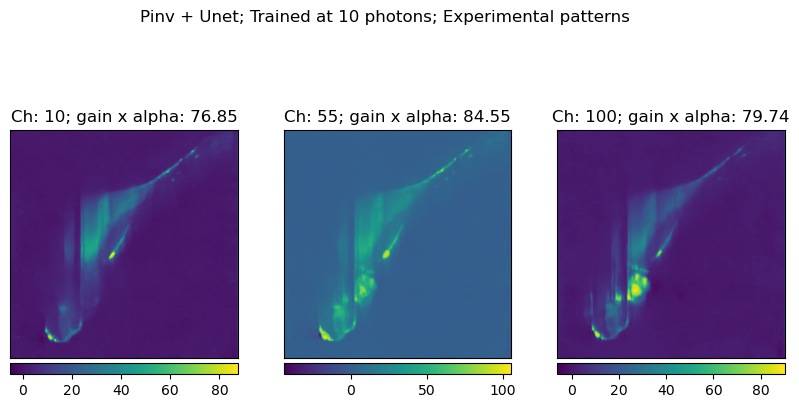

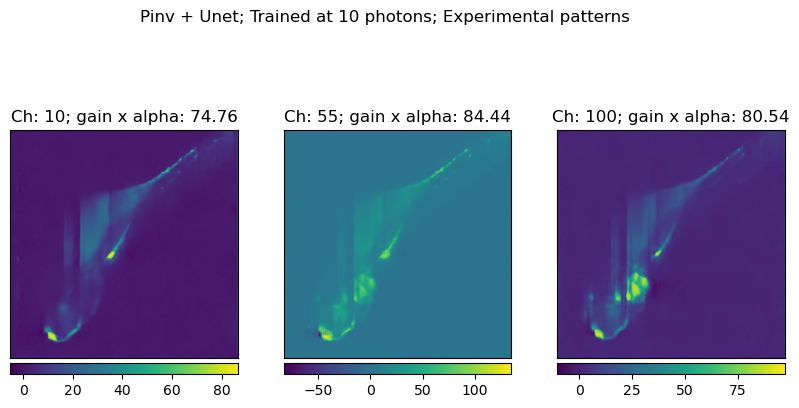

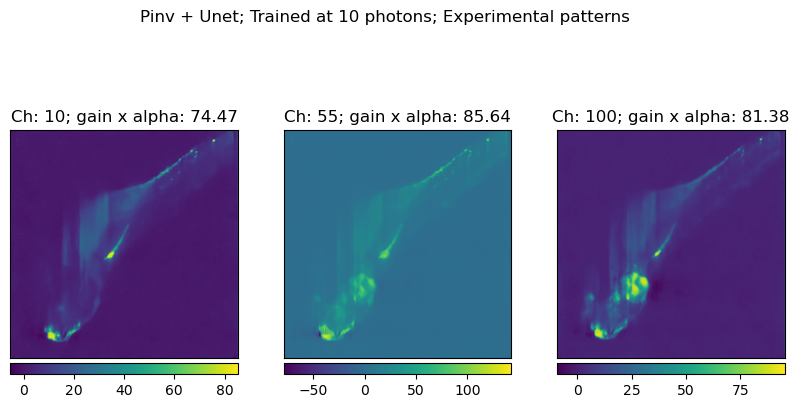

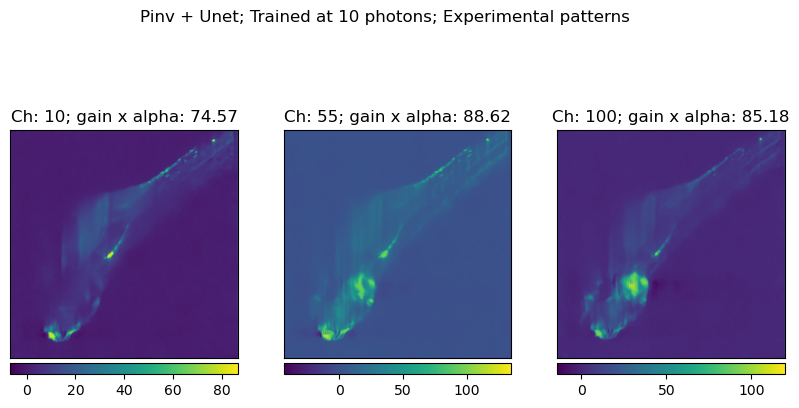

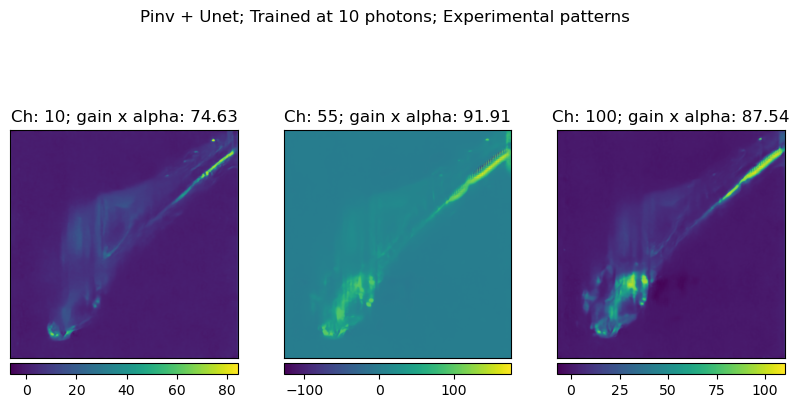

...

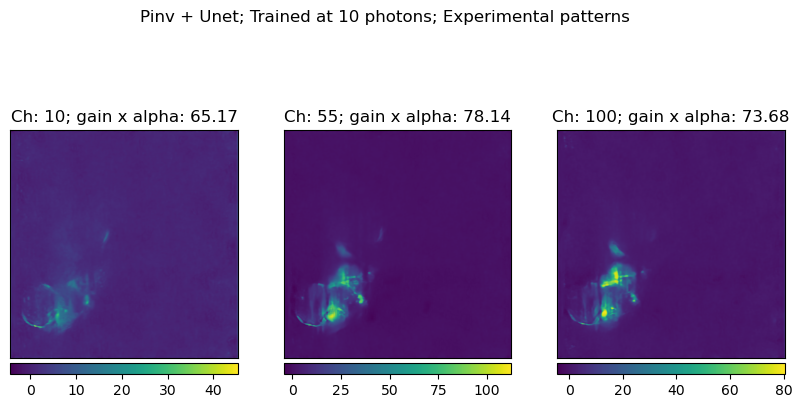

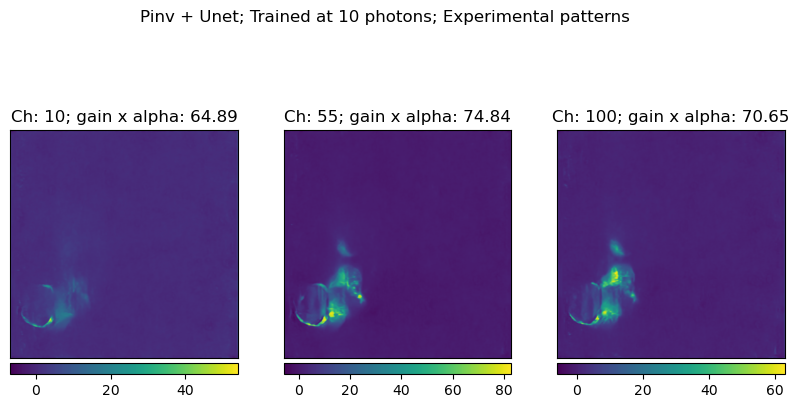

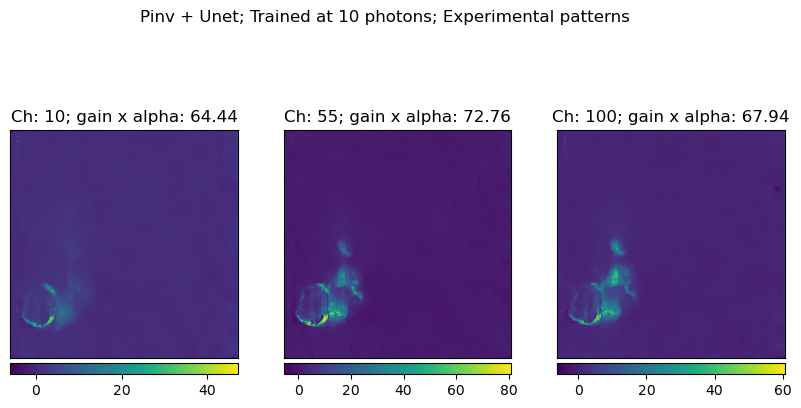

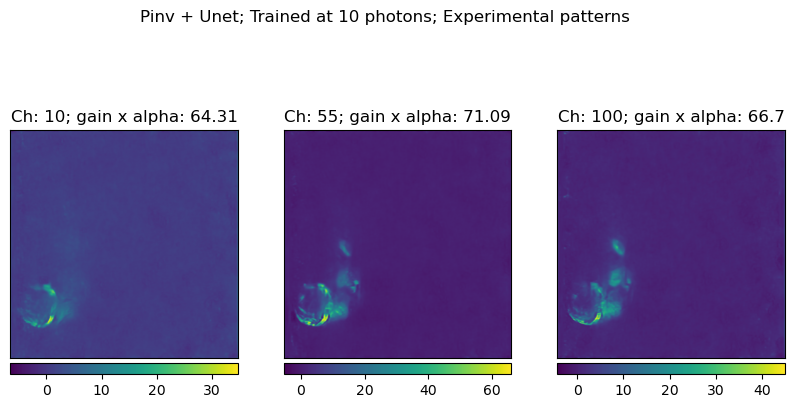

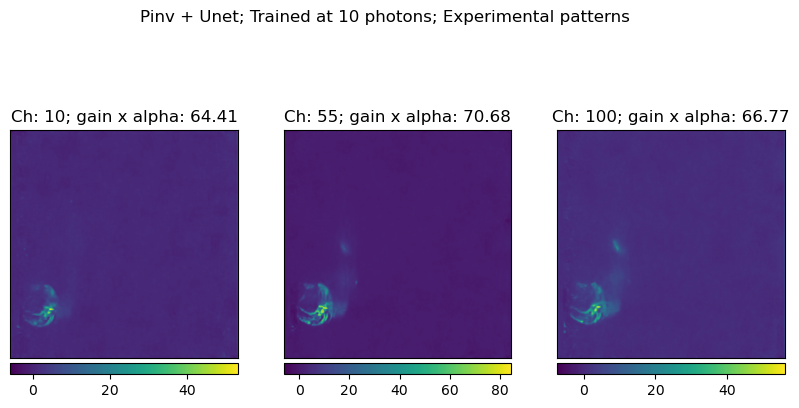

In [ ]:

alpha = 10 # in photons/pixels
save_folder = 'Reconstruction/hypercube/' + f'pinvnet{alpha}'

# Load net
net_prefix = f'pinv-net_unet_imagenet_ph_50'
net_suffix = 'N_512_M_128_epo_20_lr_0.001_sss_10_sdr_0.5_bs_20_reg_1e-07.pth'


noise = Poisson(alpha)
linop = LinearSplit(torch.from_numpy(H_exp), noise_model=noise, device=device)
prep   = UnsplitRescale(alpha)
rerange = Rerange((0, 1), (-1, 1))

denoiser = OrderedDict({"rerange": rerange, "denoi": Unet(), "rerange_inv": rerange.inverse()})
denoiser = nn.Sequential(denoiser)
title = './model/' + net_prefix + '_exp_' + net_suffix
load_net(title, denoiser, device, False)

recnet = PinvNet(linop, prep.to(device),  denoiser,  store_H_pinv = True, device=device) 
recnet.eval() # Mandantory when batchNorm is used

# Reconstruct all channels per batch
n_batch = 8 # a power of two
n_wav = Nc // n_batch

# calculate necessary values from experimental parameters
H_ones = (torch.from_numpy(H_exp)).sum(dim=-1).to(device)
even_index = range(0, 2 *M, 2)
odd_index = range(1, 2 *M, 2)

for t in T_list:

    Run = f'RUN{t:04}'

    # Load prep data
    prep_folder = '/Preprocess/'
    filename = f'{Run}_Had_{Nl}_{Nh}_{Nc}_pos.npy'
    prep_pos = np.load(Path(data_folder+prep_folder) / filename)
    
    filename = f'{Run}_Had_{Nl}_{Nh}_{Nc}_neg.npy'
    prep_neg =  np.load(Path(data_folder+prep_folder) / filename)
    
    # spectral dimension comes first
    prep_pos = np.moveaxis(prep_pos, -1, 0)
    prep_neg = np.moveaxis(prep_neg, -1, 0)
    
    # param #2
    background  = (2**15-1)*nbin
    
    prep_pos = prep_pos - background
    prep_neg = prep_neg - background
    
    nc, nl, nh = prep_neg.shape
    y = np.zeros((nc, nl, 2*nh))
    y[:,:,::2]  = prep_pos 
    y[:,:,1::2] = prep_neg
    y = torch.from_numpy(y)
    
    print(f'Loaded: {filename[:-8]}')
    print(f'Pos data: range={prep_pos.max() - prep_pos.min()} counts; mean={prep_pos.mean()} counts')  
    
    y = y.to(device)
    y = y.view(-1,1,N,2*M) 
    
    rec = np.zeros((Nc, N, N))
    beta = np.zeros(Nc)
    
    with torch.no_grad():
        for b in range(n_batch):       
            ind = range(b*n_wav, (b+1)*n_wav)            
            m = y[ind,:,:].to(device, torch.float32)
            y_unsplit = m[..., even_index] - m[..., odd_index]
            z =  m[..., even_index] + m[..., odd_index]

            mu = torch.mean(z, dim=-1, keepdim=True)
            alpha =  ((2 / N) * (mu - 2 * mudark) / gain).to(device)
            alpha = torch.amax(alpha, -2, keepdim=True)
            norm = alpha*gain

            print(f'reconstructing batch {ind.start}--{ind.stop}')
            m = y_unsplit/norm

            x_hat = recnet.pinv(m)
            x_hat = x_hat.squeeze()
            x_hat = x_hat.unsqueeze(1)
            
            x_tilde = recnet.denoi(x_hat)
            rec_gpu = x_tilde * norm # denormalise
            rec[ind,:,:] = rec_gpu.cpu().detach().numpy().squeeze()
            beta[ind] = norm.cpu().detach().numpy().squeeze()
                    
        rec = np.moveaxis(rec, 0, -1) # spectral channel is now the last axis
        
        if save_rec:
            alpha = 10
            Path(data_folder+save_folder).mkdir(parents=True, exist_ok=True)
            
            save_filename = filename[:-20].replace('Had', f'rec_pinvnet{alpha}_exp') + f'_{N}x{N}x{nc}.npy'
            np.save(Path(data_folder+save_folder) / save_filename, rec)
            
            save_filename = filename[:-20].replace('Had', f'beta_pinvnet{alpha}_exp') + f'_{N}x{N}x{nc}.npy'
            np.save(Path(data_folder+save_folder) / save_filename, beta)
            
        # Plot
        fig, axs = plt.subplots(1, 3, figsize=(10,5))
        fig.suptitle(f'Pinv + Unet; Trained at {alpha} photons; Experimental patterns')
        
        for i, c in enumerate(channel):
            im = axs[i].imshow(rec[:,:,c])
            axs[i].set_title(f'Ch: {c}; gain x alpha: {beta[c]:.4}')
            add_colorbar(im, 'bottom')
            
        noaxis(axs)
            
        if save_fig:
            save_filename = filename[:-20].replace('Had',f'rec_pinvnet{alpha}_exp') + f'_{N}x{N}x{nc}.png'
            plt.savefig(Path(data_folder+save_folder)/save_filename, bbox_inches='tight', dpi=600)
    
del recnet

### PINV

Reconstruction using the pseudoinverse only

Loaded: RUN0004_Had_512_128_128
Pos data: range=30929.0 counts; mean=9391.822192072868 counts
reconstructing batch 0--16
reconstructing batch 16--32
reconstructing batch 32--48
reconstructing batch 48--64
reconstructing batch 64--80
reconstructing batch 80--96
reconstructing batch 96--112
reconstructing batch 112--128
Loaded: RUN0005_Had_512_128_128
Pos data: range=9803.0 counts; mean=9372.537360072136 counts
reconstructing batch 0--16
reconstructing batch 16--32
reconstructing batch 32--48
reconstructing batch 48--64
reconstructing batch 64--80
reconstructing batch 80--96
reconstructing batch 96--112
reconstructing batch 112--128
Loaded: RUN0006_Had_512_128_128
Pos data: range=7724.0 counts; mean=9408.137484073639 counts
reconstructing batch 0--16
reconstructing batch 16--32
reconstructing batch 32--48
reconstructing batch 48--64
reconstructing batch 64--80
reconstructing batch 80--96
reconstructing batch 96--112
reconstructing batch 112--128
Loaded: RUN0007_Had_512_128_128
Pos data: 

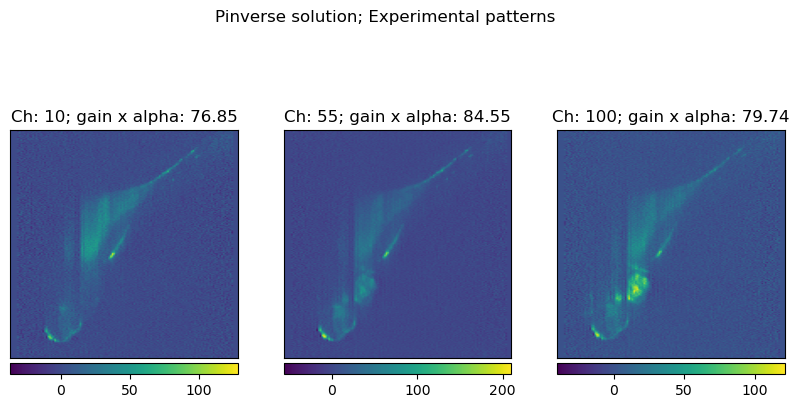

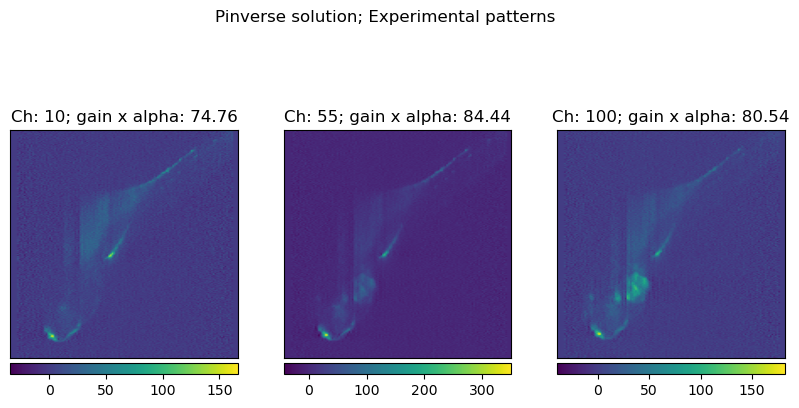

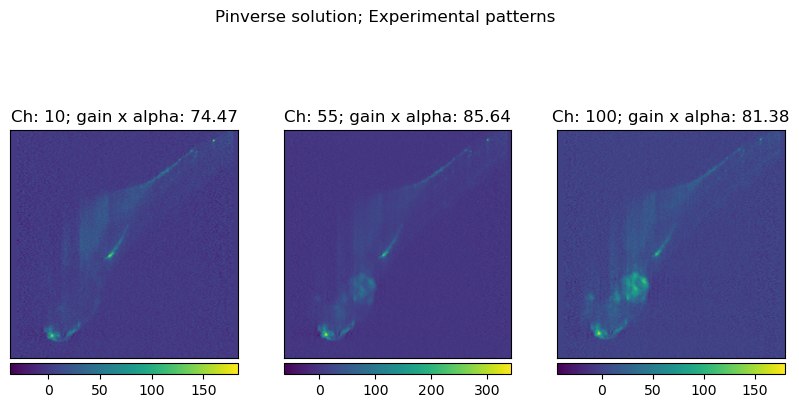

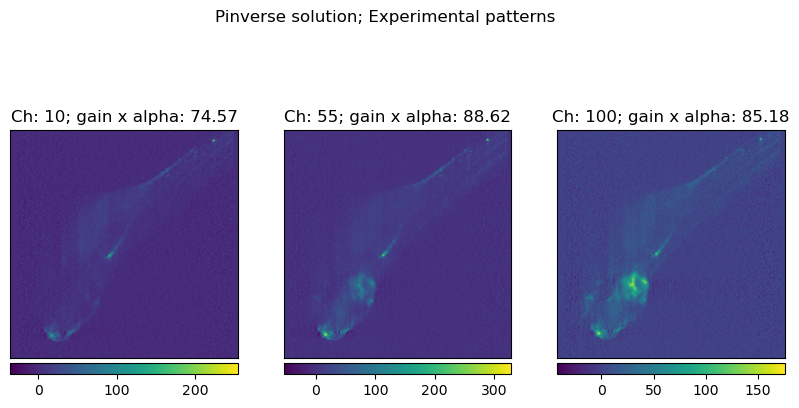

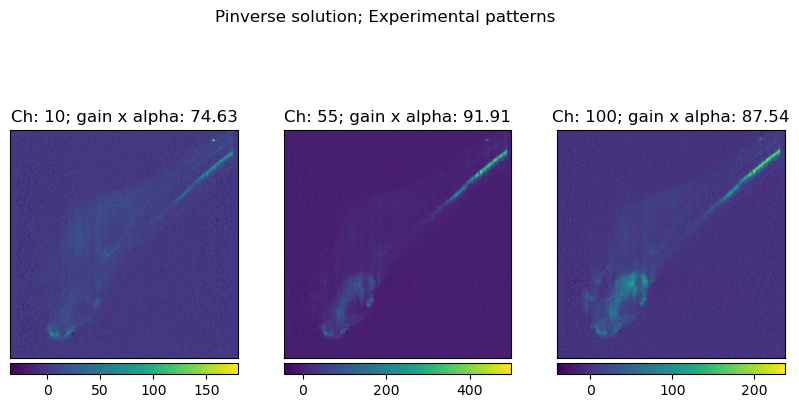

...

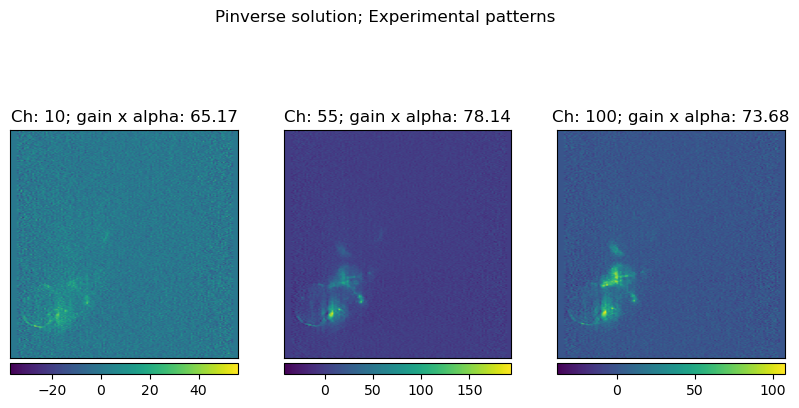

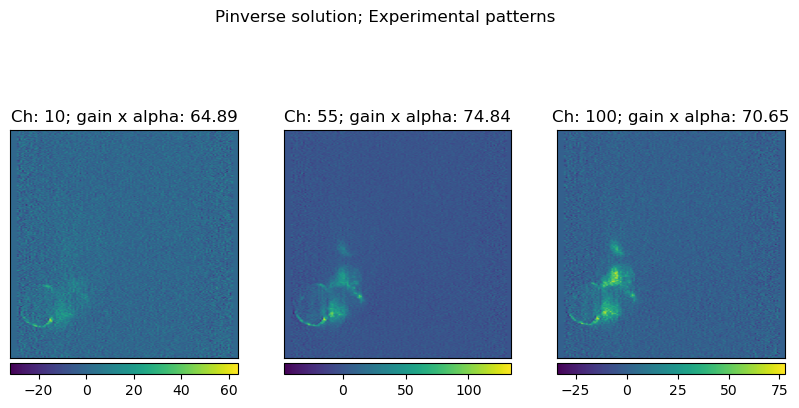

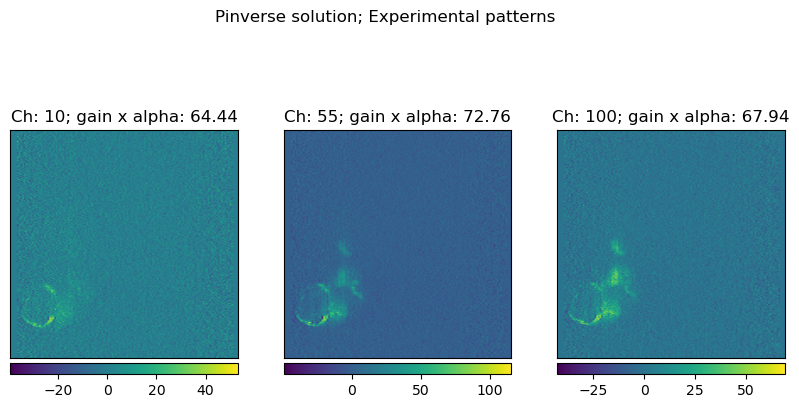

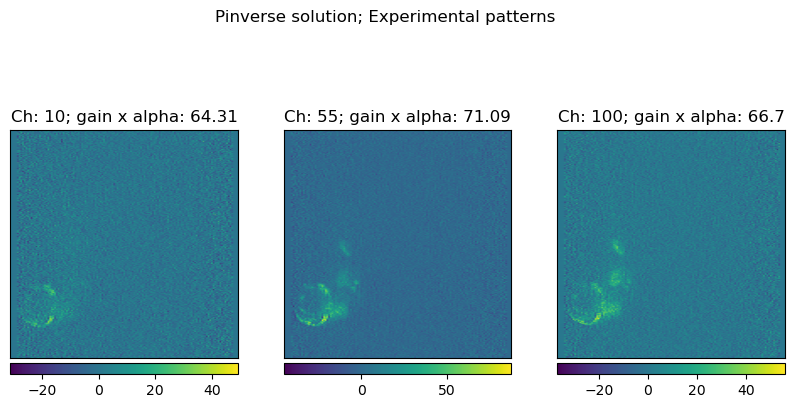

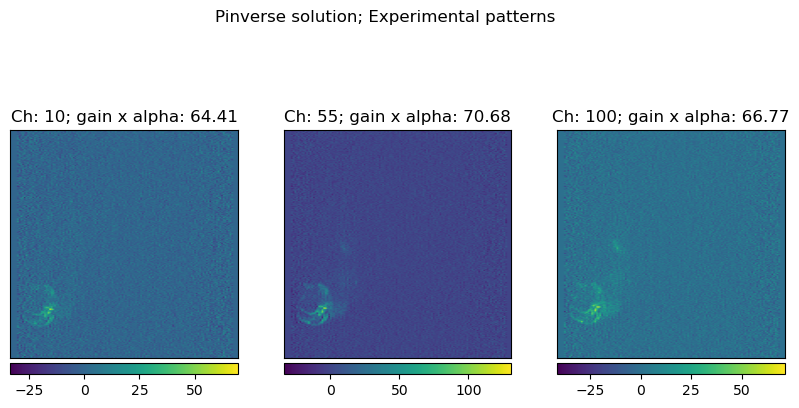

In [5]:


save_folder = '/Reconstruction/hypercube/pinv'

recnet = PinvNet(linop, store_H_pinv = True, device=device) 
recnet.eval() # Mandantory when batchNorm is used

# Reconstruct all channels per batch
n_batch = 8 # a power of two
n_wav = Nc // n_batch

for t in T_list:

    Run = f'RUN{t:04}'

    # Load prep data
    prep_folder = '/Preprocess/'
    filename = f'{Run}_Had_{Nl}_{Nh}_{Nc}_pos.npy'
    prep_pos = np.load(Path(data_folder+prep_folder) / filename)
    
    filename = f'{Run}_Had_{Nl}_{Nh}_{Nc}_neg.npy'
    prep_neg =  np.load(Path(data_folder+prep_folder) / filename)
    
    # spectral dimension comes first
    prep_pos = np.moveaxis(prep_pos, -1, 0)
    prep_neg = np.moveaxis(prep_neg, -1, 0)
    
    # param #2
    background  = (2**15-1)*nbin
    
    prep_pos = prep_pos - background
    prep_neg = prep_neg - background
    
    nc, nl, nh = prep_neg.shape
    y = np.zeros((nc, nl, 2*nh))
    y[:,:,::2]  = prep_pos 
    y[:,:,1::2] = prep_neg 
    y = torch.from_numpy(y)
    
    print(f'Loaded: {filename[:-8]}')
    print(f'Pos data: range={prep_pos.max() - prep_pos.min()} counts; mean={prep_pos.mean()} counts')  
    
    y = y.to(device)
    y = y.view(-1,1,N,2*M) 
    
    rec = np.zeros((Nc, N, N))
    beta = np.zeros(Nc)
    
    with torch.no_grad():
        for b in range(n_batch):       
            ind = range(b*n_wav, (b+1)*n_wav)            
            m = y[ind,:,:].to(device, torch.float32)
            y_unsplit = m[..., even_index] - m[..., odd_index]
            z =  m[..., even_index] + m[..., odd_index]

            mu = torch.mean(z, dim=-1, keepdim=True)
            alpha =  ((2 / N) * (mu - 2 * mudark) / gain).to(device)
            alpha = torch.amax(alpha, -2, keepdim=True)
            norm = alpha*gain

            print(f'reconstructing batch {ind.start}--{ind.stop}')
            m = y_unsplit/norm

            x_hat = recnet.pinv(m)
            x_hat = x_hat.squeeze()
            x_tilde = x_hat.unsqueeze(1)
            
            rec_gpu = x_tilde * norm # denormalise
            rec[ind,:,:] = rec_gpu.cpu().detach().numpy().squeeze()
            beta[ind] = norm.cpu().detach().numpy().squeeze()
                    
        rec = np.moveaxis(rec, 0, -1) # spectral channel is now the last axis
        
        if save_rec:
            Path(data_folder+save_folder).mkdir(parents=True, exist_ok=True)
            
            save_filename = filename[:-20].replace('Had', f'rec_pinv_exp') + f'_{N}x{N}x{nc}.npy'
            np.save(Path(data_folder+save_folder) / save_filename, rec)
            
            save_filename = filename[:-20].replace('Had', f'beta_pinv_exp') + f'_{N}x{N}x{nc}.npy'
            np.save(Path(data_folder+save_folder) / save_filename, beta)
            
        # Plot
        fig, axs = plt.subplots(1, 3, figsize=(10,5))
        fig.suptitle(f'Pinverse solution; Experimental patterns')
        
        for i, c in enumerate(channel):
            im = axs[i].imshow(rec[:,:,c])
            axs[i].set_title(f'Ch: {c}; gain x alpha: {beta[c]:.4}')
            add_colorbar(im, 'bottom')
            
        noaxis(axs)
            
        if save_fig:
            save_filename = filename[:-20].replace('Had',f'rec_pinv_exp') + f'_{N}x{N}x{nc}.png'
            plt.savefig(Path(data_folder+save_folder)/save_filename, bbox_inches='tight', dpi=600)
    
del recnet